# PC03 — Thiết kế thực nghiệm, lựa chọn thuật toán và số cụm

> **Cách đọc:** Kết quả và nhận xét chính hiển thị trực tiếp. Nhấn **Xem chi tiết** để mở bảng đối chiếu; nhật ký tiến trình cũng được thu gọn. Các phép tính và dữ liệu vẫn được giữ đầy đủ.

## Mục tiêu nghiệp vụ
Một mô hình có chỉ số đẹp chưa chắc tạo ra nhóm dễ hiểu hoặc hữu ích. Ngược lại, ép khách vào các nhãn quen thuộc có thể tạo câu chuyện không được dữ liệu hỗ trợ. PC03 cân bằng **cấu trúc thống kê, độ ổn định, quy mô nhóm và khả năng diễn giải**.

Notebook thực sự huấn luyện lại 14 cấu hình K-Means, khảo sát k=2–8 ở hai cách biểu diễn, rồi giữ một số ứng viên. Sau đó kiểm seed và đối chứng Hierarchical trên cùng mẫu. Không dùng nhãn k=3 của bản trước để huấn luyện hoặc đánh giá mô hình mới.

## Đầu vào và đầu ra
Đầu vào là RFM được kiểm chứng, không gồm `customer_id` hay nhãn nghiệp vụ. Đầu ra gồm cấu hình, chỉ số, quy mô cụm, hồ sơ sơ bộ, sample ID, tâm/scaler và một **đề xuất kỹ thuật**. PC04 tiếp tục thẩm định ý nghĩa nhóm, PC05 chốt mức sẵn sàng sử dụng.



## Cách đọc thuật ngữ và kết quả

- **Recency:** số ngày từ đơn delivered gần nhất đến 31/12/2022.
- **Frequency:** số đơn delivered đủ điều kiện của một khách.
- **Monetary:** tổng tiền sau giảm giá của các đơn đó, chưa là lợi nhuận hoặc thực thu.
- **Cụm:** nhóm khách do thuật toán tạo; mã nhóm chỉ để nhận diện.
- **Mẫu số:** tổng khách hoặc tổng đơn dùng để tính tỷ lệ; luôn đọc đúng phạm vi cạnh bảng.

Các ký hiệu và công thức cần thiết được giải thích ngay tại mục sử dụng.


## Chuẩn bị môi trường và nguồn dữ liệu

Notebook tự tìm thư mục dự án và nạp notebook hỗ trợ 00. RFM được tính từ raw/common và đối soát trực tiếp với dòng hàng nguồn; không đọc kết quả phân cụm cũ hay JSON mô hình. PC01–PC02 chưa huấn luyện. PC03 thử và chọn mô hình mới; PC04–PC06 tự huấn luyện lại khi chạy ở kernel riêng. Trong cùng kernel, các phép tính được dùng lại từ bộ nhớ.

Mặc định lượt là combined_v1. Nếu CSV của lượt đó đã tồn tại và khác kết quả mới, chương trình dừng lưu; chọn tên DATATHON_MODEL_RUN mới hoặc chủ động sao lưu/xóa CSV cũ. Kết quả cũ không quyết định lựa chọn mô hình.


In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

# Nạp định nghĩa hỗ trợ riêng, không sửa file Python dùng chung của nhóm.
_support_path = ROOT / 'notebook/05_phan_khuc_khach_hang/00_ham_ho_tro_phan_cum.ipynb'
_support_doc = json.loads(_support_path.read_text(encoding='utf-8'))
for _cell_index, _cell in enumerate(_support_doc['cells']):
    if _cell['cell_type'] == 'code':
        exec(compile(''.join(_cell['source']), f'{_support_path}:cell{_cell_index+1}', 'exec'), globals())

from ham_dung_chung import segmentation_study
sys.dont_write_bytecode = True
Study = phan_cum_tich_hop().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "combined_v1")
study = Study(ROOT, "PC03")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC03 | Lượt mô hình: combined_v1


## PC03.1 — Thiết kế thí nghiệm và tiêu chí ra quyết định

**Câu hỏi: thử những mô hình nào và chọn theo tiêu chí gì?**

Mô hình chính thử 14 cấu hình: hai cách biểu diễn TN1/TN2, mỗi cách dùng số cụm từ 2 đến 8. Tất cả fit trên cùng khách đủ điều kiện. Silhouette dùng một mẫu cố định 5.000 khách; Davies–Bouldin và Inertia dùng toàn tập.

Giữ cùng nguồn, phạm vi và cách lấy mẫu để so sánh nhất quán. Không tự chốt ba nhóm trước khi xem kết quả. Quy tắc sàng lọc, kiểm seed và hồ sơ nghiệp vụ được công bố ở các mục sau; không gọi một chỉ số cao là bằng chứng mô hình tối ưu cho mọi mục tiêu.


In [2]:
design=pd.DataFrame([{'Mục':'Dữ liệu','Quy tắc':'RFM toàn lịch sử delivered, R mốc31/12/2022'}, {'Mục':'TN1','Quy tắc':'RFM gốc → StandardScaler'}, {'Mục':'TN2','Quy tắc':'R gốc, log1p(F,M) → StandardScaler'}, {'Mục':'k','Quy tắc':'2..8'}, {'Mục':'KMeans','Quy tắc':'k-means++, n_init10, seed42, max_iter300'}, {'Mục':'Đánh giá','Quy tắc':'Silhouette cùng5000 khách; DB và Inertia toàn tập'}])
study.table('design','Thiết kế thực nghiệm',design);


,Mục,Quy tắc
0,Dữ liệu,"RFM toàn lịch sử delivered, R mốc31/12/2022"
1,TN1,RFM gốc → StandardScaler
2,TN2,"R gốc, log1p(F,M) → StandardScaler"
3,k,2..8
4,KMeans,"k-means++, n_init10, seed42, max_iter300"
5,Đánh giá,Silhouette cùng5000 khách; DB và Inertia toàn tập


## PC03.2 — K-Means: hàm mục tiêu và các bước thực hiện

**Câu hỏi: K-Means gán khách vào nhóm như thế nào?**

Mỗi khách là một điểm gồm ba giá trị RFM đã biến đổi. Thuật toán chọn số tâm bằng số cụm cần thử, gán khách vào tâm gần nhất, tính lại tâm bằng trung bình các khách trong cụm và lặp lại.

Khoảng cách bình phương từ khách đến tâm:

$$d^2(z_i,\mu_c)=\sum_{j=1}^{3}(z_{ij}-\mu_{cj})^2$$

z_i là bộ ba đã biến đổi của khách thứ i; $\mu_c$ là tâm cụm thứ c; j chỉ một trong ba cột. z_ij và $\mu_{cj}$ là giá trị của khách và tâm trên đúng cột đó. d² là tổng ba chênh lệch bình phương. Không đưa mã khách vào khoảng cách.

K-Means làm nhỏ tổng khoảng cách bình phương:

$$J=\sum_{c=1}^{k}\sum_{i\in C_c}\|z_i-\mu_c\|^2$$

J là tổng sai khác trong cụm, cũng gọi là Inertia; k là số cụm; C_c là các khách đang thuộc cụm thứ c. Dấu chuẩn bình phương trong công thức là khoảng cách bình phương vừa giải thích ở trên.

Tâm mới của một cụm được tính bằng:

$$\mu_c=\frac{1}{|C_c|}\sum_{i\in C_c}z_i$$

Số khách của cụm là |C_c|. Lấy trung bình riêng trên từng cột để được ba tọa độ tâm; tâm không nhất thiết trùng một khách thực tế.

Dự án dùng k-means++, 10 lần khởi tạo, seed 42 và tối đa 300 vòng mỗi lần. Nhiều khởi tạo giảm phụ thuộc một bộ tâm ban đầu; hội tụ chưa chứng minh tìm được nghiệm tốt nhất tuyệt đối.


In [4]:
# Always train from current raw/common; existing result files are never model input.
Workflow = phan_cum_tich_hop().Workflow
train_model = True
independent_audit = phan_cum_tich_hop().independent_audit
study.table('source_reconciliation','Đối soát độc lập trước huấn luyện',independent_audit(ROOT))
workflow = Workflow(ROOT, label=MODEL_LABEL)
workflow.audit(); workflow.prepare(); workflow.behavior()
require(workflow.features.customer_id.tolist() == study.f.customer_id.tolist(), 'Khác tập khách RFM')
grid = workflow.experiments()
study.table('experiment_grid','14 cấu hình huấn luyện mới từ nguồn',grid);


,Số đơn,eligible_orders,Số khách,exact_net_total,all_order_net_exact_match_raw,reference,method
0,646945,516716,85115,12518175957.20,True,independent raw/common reconciliation,Exact Decimal sum of all raw items; one-to-one...


,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.828
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.765
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,1.032
3,TN1,5,0.400697,0.784373,42122.258897,0.039911,0.301944,1.125
4,TN1,6,0.400804,0.780048,33170.523489,0.019597,0.281090,1.515
5,TN1,7,0.391050,0.830567,28932.962652,0.010903,0.279469,1.344
6,TN1,8,0.397023,0.836701,25818.567363,0.009387,0.255313,1.578
7,TN2,2,0.468739,0.787364,109471.395139,0.498479,0.501521,0.625
8,TN2,3,0.385208,0.939087,75069.760434,0.296516,0.377818,0.750
9,TN2,4,0.333022,1.038917,61238.684971,0.210468,0.308442,1.329


## PC03.3 — Inertia, Silhouette và Davies–Bouldin: công thức và cách đọc

**Câu hỏi: các cụm có gọn và tách biệt không?**

**Inertia:** tổng khoảng cách bình phương đến tâm đã giải thích ở mục K-Means. Tăng số cụm thường làm nó giảm, nên không chỉ lấy giá trị thấp nhất để chọn số cụm. Biểu đồ Elbow giúp tìm nơi lợi ích thêm cụm bắt đầu giảm; có thể không có điểm gãy rõ.

**Silhouette:** với một khách, gọi a(i) là khoảng cách trung bình đến các khách khác cùng cụm; b(i) là khoảng cách trung bình đến cụm khác gần nhất. Để tìm cụm khác gần nhất, tính trung bình khoảng cách tới từng cụm khác rồi lấy số nhỏ nhất; không chỉ lấy một người gần nhất.

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$$

s(i) là Silhouette của khách thứ i; max là chọn số lớn hơn trong a(i), b(i). Gần 1 là phân tách thuận lợi, gần 0 là khó phân biệt; âm cho thấy trung bình gần nhóm khác hơn. Đây không phải xác suất đúng/sai.

$$S=\frac{1}{m}\sum_{i=1}^{m}s(i)$$

S là trung bình Silhouette của m khách được đánh giá. Dự án dùng cùng 5.000 khách để giảm chi phí; khoảng cách được tính trong mẫu này. Không gọi S=0,45 là độ chính xác 45%.

**Davies–Bouldin:** so độ rộng của hai cụm với khoảng cách giữa tâm của chúng:

$$DB=\frac{1}{k}\sum_{c=1}^{k}\max_{d\ne c}\frac{A_c+A_d}{D_{cd}}$$

| Ký hiệu trong công thức DB | Ý nghĩa |
|---|---|
| k | Số cụm |
| c, d | Hai cụm khác nhau đang so sánh |
| A_c, A_d | Trung bình khoảng cách từ khách trong mỗi cụm tới tâm cụm của họ |
| D_cd | Khoảng cách giữa hai tâm cụm |
| max | Với mỗi cụm, chọn tỷ số lớn nhất khi so với các cụm còn lại |
| DB | Trung bình những tỷ số bất lợi nhất đó |

Hai cụm gọn và tâm xa nhau cho tỷ số thấp. DB thấp thường thuận lợi hơn; DB không phải phần trăm lỗi và không bị giới hạn ở 1. Trong bảng chính, DB tính toàn tập còn Silhouette tính mẫu, nên hai chỉ số có thể ưu tiên số cụm khác nhau. Đọc thêm quy mô, hồ sơ và độ ổn định thay vì chọn theo một con số.


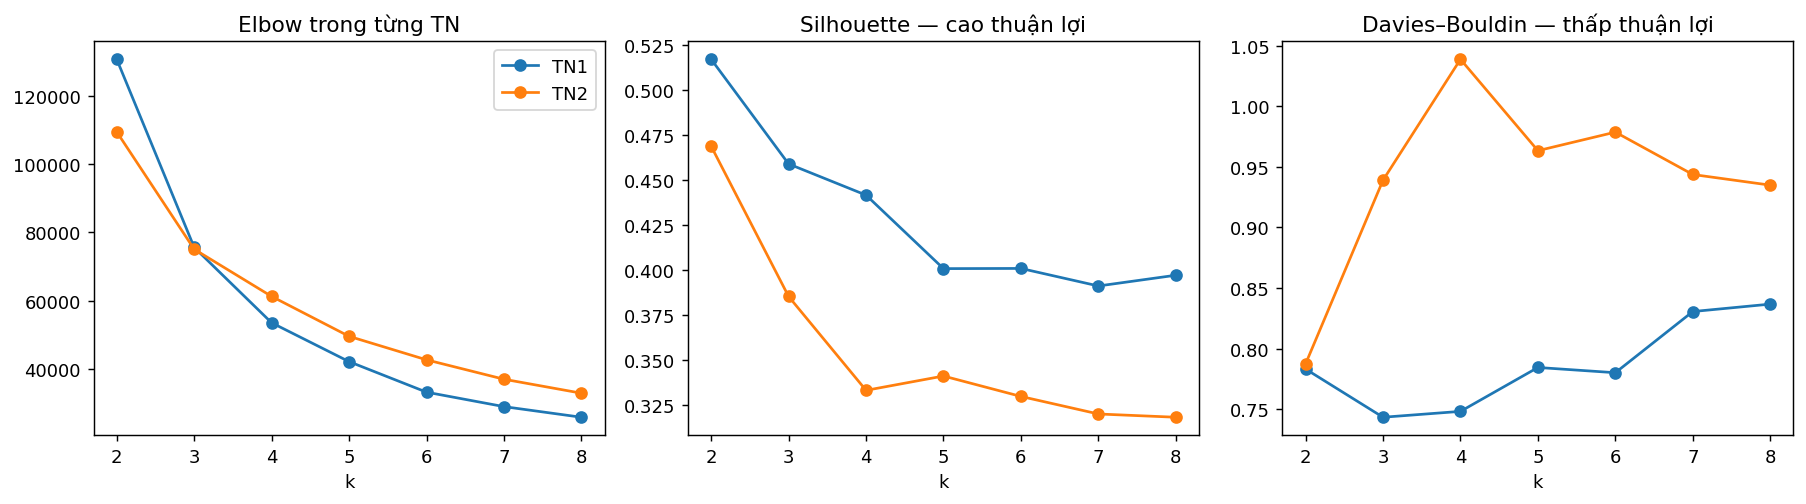

Silhouette cao nhất: TN1, k=2 (0.5171); DB thấp nhất: TN1, k=3 (0.7433). Nếu khác nhau, cần đọc quy mô và hồ sơ, không kết luận một chỉ số quyết định tất cả.

In [6]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for name,g in grid.groupby('variant'):
 for ax,col,title in zip(axes,['inertia','silhouette_sample','davies_bouldin_full'],['Elbow trong từng TN','Silhouette — cao thuận lợi','Davies–Bouldin — thấp thuận lợi']):ax.plot(g.k,g[col],marker='o',label=name);ax.set(title=title,xlabel='k')
axes[0].legend();study.fig('model_metrics','Ba góc nhìn lựa chọn mô hình',fig)
best_s=grid.loc[grid.silhouette_sample.idxmax()];best_db=grid.loc[grid.davies_bouldin_full.idxmin()]
study.note(f'Silhouette cao nhất: {best_s.variant}, k={int(best_s.k)} ({best_s.silhouette_sample:.4f}); DB thấp nhất: {best_db.variant}, k={int(best_db.k)} ({best_db.davies_bouldin_full:.4f}). Nếu khác nhau, cần đọc quy mô và hồ sơ, không kết luận một chỉ số quyết định tất cả.')

## PC03.4 — Quy mô cụm, shortlist và đánh đổi k=2/3/4

**Câu hỏi: vì sao không chọn ngay cấu hình có Silhouette cao nhất?**

Một cấu hình có thể tạo nhóm quá nhỏ hoặc hồ sơ khó sử dụng. Dự án lọc những cấu hình mà cụm nhỏ nhất có ít nhất 1% tổng khách, xếp hạng Silhouette từ cao xuống và DB từ thấp lên, cộng hai thứ hạng rồi giữ ba ứng viên.

Ngưỡng 1% là lựa chọn thiết kế của nghiên cứu, không phải quy định của K-Means. Tổng hạng dễ hiểu nhưng không biểu diễn mức chênh lệch chỉ số. Vì vậy phải đọc cả số thực tế, hồ sơ trên thang gốc và kiểm seed.

Hai cụm thường gọn về số mức; ba hoặc bốn cụm có thể thêm chi tiết. Chi tiết chỉ có ích khi phần tách thêm khác nhau rõ và có câu hỏi sử dụng, không phải vì nhiều cụm luôn tốt hơn.


In [7]:
study.table('cluster_balance','Quy mô cụm theo cấu hình',grid[['variant','k','min_cluster_share','max_cluster_share']])
study.table('shortlist','Ba ứng viên kỹ thuật',workflow.shortlist)
profiles=pd.read_csv(workflow.out/'candidate_profiles.csv')
study.table('candidate_k234','Hồ sơ k2/3/4 của TN1',profiles[(profiles.variant=='TN1') & profiles.k.isin([2,3,4])])
study.note('Hai cụm có thể chỉ tách mức giá trị; ba/bốn cụm có thể bổ sung hoạt động hoặc chia nhỏ đuôi. Phải kiểm hồ sơ thực tế, không mặc định nhiều cụm hơn hữu ích hơn.')

,Thí nghiệm,Số cụm,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất
0,TN1,2,0.222511,0.777489
1,TN1,3,0.120719,0.473971
2,TN1,4,0.044234,0.402867
3,TN1,5,0.039911,0.301944
4,TN1,6,0.019597,0.281090
5,TN1,7,0.010903,0.279469
6,TN1,8,0.009387,0.255313
7,TN2,2,0.498479,0.501521
8,TN2,3,0.296516,0.377818
9,TN2,4,0.210468,0.308442


,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds,Tổng hạng
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.765,4.0
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.828,5.0
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,1.032,6.0


,Thí nghiệm,Số cụm,Nhóm,Số khách,R trung vị,F trung vị,M trung vị
0,TN1,2,0,18939,271.0,14.0,354134.310
1,TN1,2,1,66176,1592.0,2.0,52773.190
2,TN1,3,0,40342,598.0,5.0,124473.995
3,TN1,3,1,10275,244.0,19.0,477244.080
4,TN1,3,2,34498,2307.0,1.0,29651.965
5,TN1,4,0,34290,747.0,4.0,88140.730
6,TN1,4,1,31120,2390.0,1.0,28113.800
7,TN1,4,2,3765,191.0,27.0,674514.020
8,TN1,4,3,15940,328.0,12.0,312238.310


Hai cụm có thể chỉ tách mức giá trị; ba/bốn cụm có thể bổ sung hoạt động hoặc chia nhỏ đuôi. Phải kiểm hồ sơ thực tế, không mặc định nhiều cụm hơn hữu ích hơn.

## PC03.5 — Ổn định khởi tạo và Adjusted Rand Index

**Câu hỏi: đổi tâm ban đầu có làm cách chia khách thay đổi nhiều không?**

Chạy lại ba ứng viên với seed 7, 21 và 84, rồi so với nhãn của lượt seed 42. ARI đo mức đồng thuận giữa hai cách chia, có điều chỉnh mức giống nhau có thể xuất hiện ngẫu nhiên:

$$ARI=\frac{I-E[I]}{\tfrac12(A+B)-E[I]}$$

I là số cặp khách được xếp cùng nhóm trong cả hai lần; A là số cặp cùng nhóm ở lần đầu; B là số cặp cùng nhóm ở lần sau; E[I] là số cặp cùng nhóm chung kỳ vọng nếu ghép ngẫu nhiên theo kích thước các nhóm. ARI so quan hệ giữa khách, không so số nhãn một cách máy móc.

ARI bằng 1 nghĩa là hai cách chia giống nhau, kể cả đổi tên nhóm. Gần 0 là gần mức đồng thuận ngẫu nhiên và có thể âm.

Chọn ứng viên đầu tiên theo shortlist có ARI trung bình từ 0,90; dừng nếu không có ứng viên đạt. Đây là ổn định trước khởi tạo, chưa phải ổn định qua thời gian hoặc độ chính xác dự báo.


In [9]:
stable = workflow.stability() if train_model else pd.read_csv(workflow.out / "seed_stability.csv");study.table('seed_stability','Ổn định các ứng viên',stable)
chosen=workflow.key
study.note(f'Đề xuất kỹ thuật sau kiểm ổn định: {chosen[0]}, k={chosen[1]}. Đọc tiếp khả năng phân biệt nhóm ở PC04; seed ổn định chưa chứng minh bền qua thời gian.')

,Thí nghiệm,Số cụm,Seed,ARI
0,TN1,3,7,0.996876
1,TN1,3,21,0.995662
2,TN1,3,84,0.997905
3,TN1,2,7,1.000000
4,TN1,2,21,1.000000
5,TN1,2,84,0.990348
6,TN1,4,7,0.987177
7,TN1,4,21,0.987187
8,TN1,4,84,0.987177


Đề xuất kỹ thuật sau kiểm ổn định: TN1, k=3. Đọc tiếp khả năng phân biệt nhóm ở PC04; seed ổn định chưa chứng minh bền qua thời gian.

## PC03.6 — Hierarchical Ward và thiết kế đối chứng công bằng

**Câu hỏi: một thuật toán khác có tìm cấu trúc nhóm tương tự không?**

Hierarchical bắt đầu từ từng khách riêng rồi ghép dần. Ward ưu tiên cặp ghép làm tăng độ phân tán ít nhất:

$$\Delta(A,B)=\frac{|A||B|}{|A|+|B|}\|\mu_A-\mu_B\|^2$$

A và B là hai cụm đang xét; |A| và |B| là số khách của từng cụm; $\mu_A$ và $\mu_B$ là tâm của hai cụm. Khoảng cách bình phương giữa tâm được nhân với phần phụ thuộc quy mô. Delta là mức tăng tổng bình phương sai khác khi ghép; Ward chọn cặp có mức tăng thấp hơn.

Bảng bổ trợ cũ so K-Means và Ward trên cùng mẫu 3.500 khách, dùng biến đổi đã chọn từ toàn tập. Đối chứng bốn thuật toán ở phần sau dùng mẫu 5.000 và scaler fit riêng trên mẫu. Hai bảng là hai thiết kế khác nhau, không trộn chỉ số hoặc gọi Ward đã chạy toàn bộ 85.115 khách.


In [11]:
hier = workflow.hierarchy() if train_model else pd.read_csv(workflow.out / "hierarchical_comparison.csv");study.table('hierarchical_comparison','Đối chứng công bằng trên mẫu',hier)
study.table('hierarchy_ari','Mức đồng thuận hai thuật toán theo k',pd.read_csv(workflow.out / 'hierarchy_agreement.csv'))
study.note('Đồng thuận thấp chưa chứng minh thuật toán sai: tiêu chí gom cụm khác nhau. Chỉ số nội bộ và hồ sơ phải được đọc cùng nhau; Đối chứng 4 thuật toán nằm ở phần bổ sung dưới đây; bảng Ward này dùng mẫu 3.500 và scaler toàn tập, không trộn với mẫu 5.000.')

,algorithm,Số cụm,fit_customers,silhouette,davies_bouldin
0,KMeans_sample,2,3500,0.512336,0.787446
1,Hierarchical_Ward_sample,2,3500,0.532819,0.741094
2,KMeans_sample,3,3500,0.457858,0.735586
3,Hierarchical_Ward_sample,3,3500,0.394450,0.797530
4,KMeans_sample,4,3500,0.447029,0.729052
5,Hierarchical_Ward_sample,4,3500,0.400933,0.751120


,Số cụm,ARI hai thuật toán
0,2,0.752306
1,3,0.503250
2,4,0.474515


Đồng thuận thấp chưa chứng minh thuật toán sai: tiêu chí gom cụm khác nhau. Chỉ số nội bộ và hồ sơ phải được đọc cùng nhau; Đối chứng 4 thuật toán nằm ở phần bổ sung dưới đây; bảng Ward này dùng mẫu 3.500 và scaler toàn tập, không trộn với mẫu 5.000.

## PC03.7 — Chỉ lưu CSV kết quả cuối

Mô hình, scaler, tâm và thông tin lựa chọn chỉ giữ trong bộ nhớ của kernel. Không đọc hoặc xuất JSON mô hình. Sau huấn luyện, chỉ lưu ket_qua_phan_cum.csv trong data/model/phan_khuc/<tên_lượt>/.

CSV có mã khách, RFM, mã cụm và tên nhóm; không chứa các dòng tham số đặc biệt. Khi khởi động kernel mới, mô hình được học lại từ nguồn theo cùng thiết kế, không khôi phục từ CSV cũ. Vì vậy việc chạy notebook độc lập lâu hơn và có thể khác khi nguồn hoặc môi trường thay đổi. Không dùng nhãn cũ làm đáp án để ép kết quả mới.


In [12]:
if train_model:
    workflow.sensitivity()
    workflow.profile()
    workflow.finish()
model_manifest = study.use_model(MODEL_LABEL)
study.table('selected_profile','Hồ sơ phương án đề xuất',workflow.profiles.reset_index(drop=True) if not train_model else workflow.profiles.reset_index())
study.note('PC04 sẽ so sâu k2/3/4 và hồ sơ nhóm. Mô hình này là đề xuất cho mô tả tập delivered, chưa là quyết định nhắm khách hoặc kết luận churn/VIP.')

,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


PC04 sẽ so sâu k2/3/4 và hồ sơ nhóm. Mô hình này là đề xuất cho mô tả tập delivered, chưa là quyết định nhắm khách hoặc kết luận churn/VIP.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [13]:
study.note("### Kết luận thực nghiệm và điều cần thẩm định nghiệp vụ")
t=workflow.grid;chosen=t[(t.variant==workflow.key[0]) & (t.k==workflow.key[1])].iloc[0]
study.note(f'Đề xuất kỹ thuật là {workflow.key[0]}, k={workflow.key[1]}, Silhouette={chosen.silhouette_sample:.4f}, DB={chosen.davies_bouldin_full:.4f}. Đây là cấu hình đã qua quy tắc shortlist/seed, không phải chiến thắng trên mọi tiêu chí. PC04 cần chứng minh phần chia thêm có hồ sơ khác và có câu hỏi sử dụng; PC05 công bố giới hạn/độ nhạy trước bàn giao.')

### Kết luận thực nghiệm và điều cần thẩm định nghiệp vụ

Đề xuất kỹ thuật là TN1, k=3, Silhouette=0.4589, DB=0.7433. Đây là cấu hình đã qua quy tắc shortlist/seed, không phải chiến thắng trên mọi tiêu chí. PC04 cần chứng minh phần chia thêm có hồ sơ khác và có câu hỏi sử dụng; PC05 công bố giới hạn/độ nhạy trước bàn giao.

## Kiểm chứng và hoàn tất phân tích

Đối soát trực tiếp nguồn, kiểm nguồn không thay đổi trong phiên và hoàn tất phân tích. Bảng/biểu đồ hiển thị trong notebook. Chỉ CSV phân cụm cuối được lưu; không đọc hoặc xuất JSON. Tính lại khi mở kernel mới, không dùng kết quả cũ làm đầu vào.


### PC03.10. Mở rộng đối chứng bốn thuật toán trên cùng 5.000 khách

**Câu hỏi: K-Means, Hierarchical, GMM và DBSCAN khác nhau ra sao trên cùng dữ liệu?**

Dùng cùng 5.000 khách và cùng StandardScaler fit trên mẫu, chỉ với TN1. K-Means, Ward và GMM thử số cụm từ 2 đến 8; DBSCAN thử 15 bộ bán kính/láng giềng. Tổng cộng 36 cấu hình. Đây là đối chứng thuật toán trên mẫu, không thay thế 14 cấu hình toàn tập TN1/TN2.

**GMM** mô tả mật độ bằng nhiều thành phần Gaussian:

$$p(z)=\sum_{c=1}^{k}\pi_c\,\mathcal{N}(z\mid\mu_c,\Sigma_c)$$

z là bộ RFM chuẩn hóa; p(z) là mật độ mô hình tại điểm đó; k là số thành phần; c chỉ từng thành phần; $\pi_c$ là trọng số không âm, tổng bằng 1; N là mật độ Gaussian với trung bình $\mu_c$ và hiệp phương sai $\Sigma_c$. Hiệp phương sai mô tả độ phân tán và hướng liên hệ các biến. Ở đây dùng nhãn thành phần có xác suất thuộc lớn nhất, chưa hiệu chỉnh xác suất thành mức chắc chắn để hành động.

**DBSCAN** gom vùng đủ mật độ:

$$N_{\varepsilon}(z)=\{x:\|x-z\|_2\le\varepsilon\}$$
$$|N_{\varepsilon}(z)|\ge min\_samples$$

z là điểm đang xét; x là một điểm khác hoặc chính nó; epsilon là bán kính khoảng cách Euclid; $N_{\varepsilon}(z)$ là những điểm trong bán kính đó. Dấu hai vạch quanh N ở công thức thứ hai đếm số điểm. min_samples là số điểm tối thiểu để được xem là điểm lõi, tính cả bản thân điểm. Thuật toán nối vùng đủ mật độ và có thể để điểm nhiễu; không đặt trước số cụm.

Bảng có thêm Calinski–Harabasz: chỉ số so mức phân tán giữa cụm với trong cụm; cao hơn thường thuận lợi. Không dùng nó như phần trăm đúng.

Cửa sàng lọc là 2–8 cụm, bao phủ ít nhất 95%, cụm nhỏ nhất ít nhất 2% toàn mẫu và GMM hội tụ. Không đạt thì chỉ hiển thị chẩn đoán, không chọn làm người thắng. DBSCAN tính chỉ số trên phần không nhiễu nên khác quần thể mô hình bao phủ toàn mẫu; luôn đọc thêm tỷ lệ nhiễu và quy mô nhóm.

PCA chỉ giúp vẽ chung hai trục, không dùng để huấn luyện mô hình này. Dấu X đỏ trong hình đối chứng là trung bình tọa độ các điểm của cụm; không có nghĩa Ward hay DBSCAN đã học tâm như K-Means.


,run_id,algorithm,params,seconds,clusters,coverage,min_cluster_share_all,max_cluster_share_all,noise_share,silhouette,davies_bouldin,calinski_harabasz,converged,eligible
0,0,K-Means,"{""k"": 2}",0.031,2,1.0000,0.2230,0.7770,0.0000,0.517195,0.771749,4985.590746,True,True
1,1,Hierarchical,"{""k"": 2}",0.578,2,1.0000,0.0994,0.9006,0.0000,0.577588,0.626214,4002.377817,True,True
2,2,GMM,"{""k"": 2}",0.093,2,1.0000,0.4004,0.5996,0.0000,0.403071,0.942643,3858.042192,True,True
3,3,K-Means,"{""k"": 3}",0.031,3,1.0000,0.1258,0.4668,0.0000,0.459519,0.736963,6301.100977,True,True
4,4,Hierarchical,"{""k"": 3}",0.500,3,1.0000,0.0994,0.6892,0.0000,0.391035,0.671263,4801.540887,True,True
5,5,GMM,"{""k"": 3}",0.109,3,1.0000,0.1688,0.4562,0.0000,0.277680,1.079512,3742.002862,True,True
6,6,K-Means,"{""k"": 4}",0.047,4,1.0000,0.0526,0.3936,0.0000,0.440145,0.751544,6611.574579,True,True
7,7,Hierarchical,"{""k"": 4}",0.500,4,1.0000,0.0994,0.4208,0.0000,0.359722,0.850121,5464.377279,True,True
8,8,GMM,"{""k"": 4}",0.234,4,1.0000,0.1266,0.3230,0.0000,0.163702,1.438315,2849.390249,True,True
9,9,K-Means,"{""k"": 5}",0.047,5,1.0000,0.0428,0.2994,0.0000,0.400478,0.791155,6623.325858,True,True


,run_id,algorithm,params,seconds,clusters,coverage,min_cluster_share_all,max_cluster_share_all,noise_share,silhouette,davies_bouldin,calinski_harabasz,converged,eligible
0,0,K-Means,"{""k"": 2}",0.031,2,1.0,0.2230,0.7770,0.0,0.517195,0.771749,4985.590746,True,True
1,1,Hierarchical,"{""k"": 2}",0.578,2,1.0,0.0994,0.9006,0.0,0.577588,0.626214,4002.377817,True,True
2,2,GMM,"{""k"": 2}",0.093,2,1.0,0.4004,0.5996,0.0,0.403071,0.942643,3858.042192,True,True


,run_id,algorithm,params,seconds,clusters,coverage,min_cluster_share_all,max_cluster_share_all,noise_share,silhouette,davies_bouldin,calinski_harabasz,converged,eligible
0,25,DBSCAN,"{""eps"": 0.49990854241722654, ""min_samples"": 5,...",0.156,2,0.9956,0.0012,0.9944,0.0044,0.678399,0.258299,98.502931,True,False


,run_id,algorithm,params,seconds,clusters,coverage,min_cluster_share_all,max_cluster_share_all,noise_share,silhouette,davies_bouldin,calinski_harabasz,converged,eligible
3,3,K-Means,"{""k"": 3}",0.031,3,1.0,0.1258,0.4668,0.0,0.459519,0.736963,6301.100977,True,True
4,4,Hierarchical,"{""k"": 3}",0.500,3,1.0,0.0994,0.6892,0.0,0.391035,0.671263,4801.540887,True,True
5,5,GMM,"{""k"": 3}",0.109,3,1.0,0.1688,0.4562,0.0,0.277680,1.079512,3742.002862,True,True


DBSCAN có thể đạt Silhouette cao nhờ một cụm lớn và nhóm rất nhỏ; đọc eligible=False, không xếp thắng. Đối chứng hiện chỉ bao phủ TN1 và mẫu đã chọn.

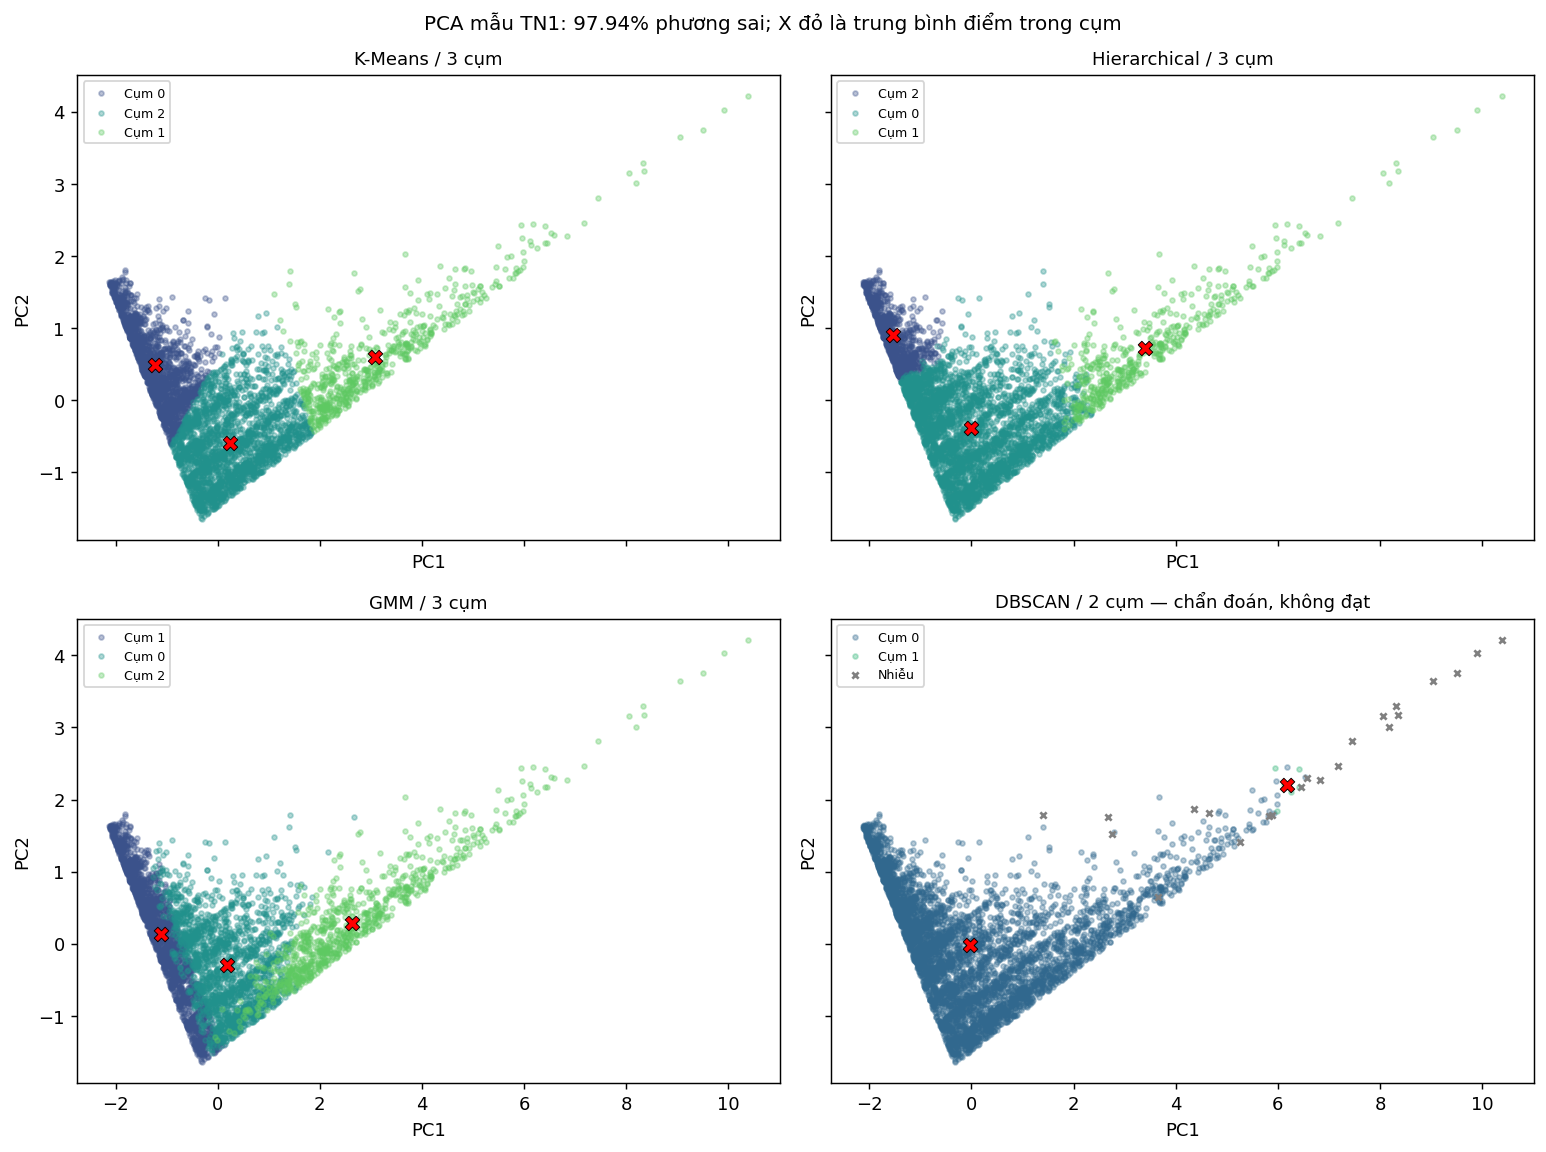

PCA chỉ hiển thị. Dấu X là trung bình của các điểm trong mỗi cụm, không phải tâm được Ward/DBSCAN học. DBSCAN không đạt chỉ là chẩn đoán; không dùng hình để kết luận chính xác.

In [14]:
compare_models = phan_cum_tich_hop().compare_models
comparison_scores = compare_models(ROOT, MODEL_LABEL)
study.table('four_algorithm_scores','36 cấu hình đối chứng TN1 trên mẫu', comparison_scores)
comparison_dir = study.model_files(MODEL_LABEL) / 'doi_chung'
representatives = pd.read_csv(comparison_dir/'representatives_eligible.csv')
study.table('eligible_representatives','Đại diện đạt sàng lọc', representatives)
ineligible = pd.read_csv(comparison_dir/'diagnostics_ineligible.csv')
study.table('ineligible_diagnostics','Chỉ chẩn đoán — không đủ điều kiện chọn', ineligible)
at_k3 = comparison_scores.loc[comparison_scores.algorithm.isin(['K-Means','Hierarchical','GMM']) & comparison_scores.params.map(lambda s:json.loads(s).get('k')==3)]
study.table('four_models_at_k3','Đối chiếu cùng k=3, cùng mẫu và scaler', at_k3)
study.note('DBSCAN có thể đạt Silhouette cao nhờ một cụm lớn và nhóm rất nhỏ; đọc eligible=False, không xếp thắng. Đối chứng hiện chỉ bao phủ TN1 và mẫu đã chọn.')
plot_comparison = phan_cum_tich_hop().plot_comparison
study.fig('four_algorithm_pca','PCA cùng không gian — không dùng để huấn luyện',plot_comparison(ROOT,MODEL_LABEL))
study.note('PCA chỉ hiển thị. Dấu X là trung bình của các điểm trong mỗi cụm, không phải tâm được Ward/DBSCAN học. DBSCAN không đạt chỉ là chẩn đoán; không dùng hình để kết luận chính xác.')


### PC03.11. Quyết định kỹ thuật và giới hạn lựa chọn k

**Câu hỏi: kết quả kỹ thuật đã đủ để quyết định kinh doanh chưa?**

Chưa. Quy tắc kỹ thuật sàng lọc theo quy mô, Silhouette, DB và seed; PC04 còn phải giải thích phần chi tiết thêm giữa hai, ba và bốn cụm. Nếu hai cụm có Silhouette tốt hơn nhưng ba cụm cho hồ sơ hữu ích hơn, phải công bố đánh đổi thay vì nói ba cụm thắng mọi chỉ số.

Bảng seed toàn tập kiểm chính mô hình được chọn; khác với kiểm seed của mô hình mẫu ở PC05. Cả hai chưa chứng minh ổn định trong tương lai. Việc chia ngân sách hoặc chăm sóc cần mục tiêu, chi phí và thử nghiệm được xác định riêng.


In [15]:
full_seed = pd.read_csv(study.model_files(MODEL_LABEL)/'selected_full_seed_stability.csv')
study.table('selected_full_seed_stability','Kiểm seed chính mô hình được chọn trên toàn tập',full_seed)
study.note('Kiểm seed toàn tập tách biệt kiểm seed trên mẫu ở PC05; cả hai chưa phải kiểm theo thời gian.')

,Seed,ari_full
0,7,0.996876
1,21,0.995662
2,84,0.997905


Kiểm seed toàn tập tách biệt kiểm seed trên mẫu ở PC05; cả hai chưa phải kiểm theo thời gian.

In [16]:
part_manifest=study.finish()

## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được hiển thị trong notebook, không suy từ phiên bản trang tài liệu hiện hành.
